# 3.3.4. Câu hỏi nghiên cứu Q5: Mức độ tập trung lượng người sở hữu theo thể loại game

### 1. Câu hỏi nghiên cứu

> **Trong mỗi thể loại game, nhóm 10% tựa game có lượng người sở hữu ước tính cao nhất chiếm bao nhiêu phần tổng lượng người sở hữu ước tính cộng gộp của thể loại đó? Mức độ tập trung này khác nhau thế nào giữa các thể loại lớn, và khác biệt có còn khi so sánh game cùng thời kỳ phát hành, cùng nhóm giá? Kết quả có vững khi thay ngưỡng top 10% bằng top 5% hoặc top 20% không?**

**Phạm vi câu hỏi:** đo sự tập trung của *ước tính ownership giữa các tựa game* trong từng thể loại. Không diễn giải tổng ownership cộng gộp thành số người chơi duy nhất: cùng một người có thể sở hữu nhiều game.

### 2. Động cơ và ý nghĩa thực tế

Hai thể loại có tổng ownership ước tính lớn có thể có cấu trúc rất khác nhau: một thể loại có thể dựa chủ yếu vào vài tựa nổi bật, trong khi thể loại khác có lượng sở hữu được chia đều hơn giữa nhiều tựa. Tỷ trọng ownership của nhóm game dẫn đầu giúp mô tả mức độ phụ thuộc vào các tựa đầu tàu trong mỗi phân khúc.

**Đối tượng hưởng lợi:** nhà phát hành, studio và nhóm nghiên cứu thị trường đang cân nhắc danh mục game theo thể loại. Nếu ownership tập trung cao, việc nhìn vào quy mô toàn thể loại có thể làm cơ hội của game điển hình trông lớn hơn thực tế. Đây là tín hiệu mô tả để đặt câu hỏi về rủi ro danh mục; không phải dự báo doanh thu, lợi nhuận hay tỷ lệ thành công.

### 3. Biến số và định nghĩa đo lường

| Biến | Vai trò |
|---|---|
| `appid` | Đơn vị phân tích; kiểm tra một dòng tương ứng một game. |
| `estimated_owners` | Dải ước tính ownership của game; tách cận dưới/cận trên và dùng trung điểm cho phân tích chính. |
| `genres` | Danh sách thể loại; dùng thể loại đầu tiên làm thể loại chính để mỗi game chỉ được tính một lần. |
| `release_date` | Tạo nhóm thời kỳ phát hành để so sánh các cohort game khác tuổi đời tích lũy. |
| `price` | Nhóm miễn phí theo giá (`price = 0`) và trả phí (`price > 0`) để kiểm soát khác biệt cơ cấu. |

Biến dẫn xuất chính:

\[
\text{Tỷ trọng top } p\% =
\frac{\sum \text{ownership midpoint của } p\% \text{ game cao nhất}}
{\sum \text{ownership midpoint của tất cả game trong nhóm}}
\]

Giá trị cao nghĩa là ownership ước tính tập trung hơn vào ít tựa game; không đồng nghĩa thị phần doanh thu hoặc số người chơi duy nhất.

### 4. Giả thuyết

- **H1:** Mức tập trung ownership khác nhau giữa các thể loại game.
- **H2:** Thể loại có khác biệt vẫn còn sau khi so sánh các nhóm game cùng thời kỳ phát hành và cùng nhóm giá.
- **H3:** Thứ tự/kết luận chính không đảo chiều khi dùng top 5%, top 10%, top 20%, hoặc cận dưới/cận trên thay trung điểm của `estimated_owners`.

### 5. Tiêu chí chiều sâu phân tích

| Tiêu chí | Thực hiện trong Q5 |
|---|---|
| **D2 — Reshaping & time** | Tạo các cohort theo thời kỳ phát hành và pivot tỷ trọng ownership theo thể loại × cohort. Đây là so sánh các nhóm game theo năm phát hành trong một snapshot, không phải chuỗi thời gian theo dõi cùng game. |
| **D3 — Derived variables** | Chuyển dải ownership thành cận dưới, cận trên, trung điểm; tính tỷ trọng ownership top 5%/10%/20%. |
| **D4 — Controlling for a confounder** | So sánh thể loại trong cùng cohort phát hành và cùng nhóm giá; chỉ dùng các tầng có đủ game ở mọi thể loại được đối chiếu. |
| **D5 — Quantifying uncertainty** | Bootstrap theo game trong từng tầng, báo khoảng tin cậy 95% cho tỷ trọng đã chuẩn hóa và chênh lệch giữa thể loại. |
| **D6 — Robustness check** | Thay ngưỡng top 5%/10%/20%; thay trung điểm bằng cận dưới/cận trên ownership; giữ rõ quy tắc ngưỡng mẫu. |

Q5 đáp ứng tối thiểu **D3, D4, D5, D6**; D2 là phân tích bổ sung theo cohort phát hành. Không thêm D1 chỉ để có merge: processed dataset đã chứa các cột cần thiết, và ghép thêm một bản sao của cùng dữ liệu không tạo thêm bằng chứng.

### 6. Giới hạn và khác biệt với các câu còn lại

Q1 nghiên cứu mối liên hệ giữa độ phủ nền tảng/ngôn ngữ và quy mô game; Q2/Q6 nghiên cứu thời lượng chơi; Q3 dự đoán hit game; Q4 tập trung DLC/achievement và review. Q5 không dự đoán một game có thành hit hay không, mà mô tả **ownership ước tính được phân bổ tập trung đến mức nào trong từng thể loại**.

`estimated_owners` là khoảng ước tính, không phải số đếm chính xác. Chọn thể loại đầu tiên bỏ qua thể loại phụ. Ownership là tích lũy, nên game cũ có thời gian tích lũy lâu hơn; cohort phát hành và giá giúp kiểm soát một phần cơ cấu nhưng không loại hết yếu tố gây nhiễu. Không thể suy ra quan hệ nhân quả, doanh thu hoặc lợi nhuận.

## 3.4.4. Phân tích câu hỏi nghiên cứu Q5: Mức độ tập trung ownership theo thể loại

### 1. Mục tiêu phân tích

Phân tích trả lời ba ý: (1) trong mỗi thể loại, bao nhiêu phần ownership ước tính cộng gộp thuộc về nhóm 10% game có ownership cao nhất; (2) sự khác biệt giữa các thể loại lớn có còn khi so sánh game cùng cohort phát hành và cùng nhóm giá; và (3) kết luận có đổi khi thay ngưỡng top 10% hoặc cách đại diện cho khoảng `estimated_owners` hay không.

Đơn vị phân tích là **một tựa game (`appid`)**. Ownership là lượng sở hữu ước tính tích lũy của tựa game trong snapshot tháng 03/2025, không phải số người chơi đang hoạt động hay số người duy nhất.

### 2. Chuẩn bị dữ liệu

Dữ liệu lấy từ `data/processed/steam_games_mar2025.csv`, gồm **89.618 dòng và 89.618 `appid` duy nhất**. Chỉ đọc năm cột cần thiết: `appid`, `estimated_owners`, `release_date`, `price`, `genres`. Không nối bảng khác vì các biến cần cho câu hỏi đã có trong cùng nguồn; không tạo phép ghép chỉ để thêm tiêu chí D1.

`estimated_owners` được công bố theo khoảng, ví dụ `20,000–50,000`. Phân tích chính dùng trung điểm khoảng. `genres` có thể chứa nhiều thể loại; lấy thể loại đầu tiên làm thể loại chính để mỗi game chỉ đóng góp một lần. Cohort phát hành là đến 2009, 2010–2014, 2015–2019, 2020–2022, 2023–2025. Giá tại snapshot được chia thành `Miễn phí` (`price = 0`) và `Trả phí` (`price > 0`); đây là phân loại theo giá quan sát, không khẳng định mô hình kinh doanh lâu dài.

### 3. Tiền xử lý dữ liệu

Các bước dưới đây được áp dụng tuần tự. Sau mỗi điều kiện lọc, mã in số dòng trước/sau và số bị loại; bảng ngay sau phần này lưu các con số đó để có thể kiểm tra mà không cần đọc mã. Thứ tự lọc quan trọng: mỗi số bị loại ở một bước là số dòng còn lại ngay trước bước đó.

1. Chuyển `price` sang số và giữ giá không âm; ngày phát hành được chuyển sang ngày tháng và phải hợp lệ, không muộn hơn 31/03/2025.
2. Tách cận dưới/cận trên ownership, tính trung điểm và chỉ giữ giá trị đọc được có trung điểm lớn hơn 0. Dòng thiếu, sai định dạng, khoảng không hợp lệ hoặc không có ownership dương không thể đóng góp hợp lệ vào tỷ trọng.
3. Đọc danh sách thể loại và giữ game xác định được thể loại chính. Mỗi game được gán đúng một thể loại để tránh đếm lặp.
4. Tạo năm/cohort phát hành và nhóm giá. Đây là tạo biến, không lọc thêm game; mã kiểm tra số dòng trước/sau vẫn bằng nhau và kiểm tra `appid` không trùng.

Không điền giá trị ownership thiếu bằng 0: 0 sẽ làm thay đổi mẫu số và có thể làm tỷ trọng tập trung sai lệch. Các phép chia cohort/nhóm giá và chọn tập so sánh được báo riêng ở phần phân tích, vì chúng chỉ giới hạn một phép so sánh chứ không thay thế tập dữ liệu nền.

In [1]:
from ast import literal_eval
from html import escape
from pathlib import Path
import re

import numpy as np
import pandas as pd
from IPython.display import SVG, display

def svg_text(text, x, y, size=16, anchor='start', weight='normal', fill='#222222', extra=''):
    return (
        f'<text x="{x}" y="{y}" text-anchor="{anchor}" font-size="{size}" '
        f'font-weight="{weight}" fill="{fill}" {extra}>{escape(str(text))}</text>'
    )

def svg_start(width, height, title, subtitle=''):
    parts = [
        f'<svg xmlns="http://www.w3.org/2000/svg" width="{width}" height="{height}" '
        f'viewBox="0 0 {width} {height}" role="img">',
        '<rect width="100%" height="100%" fill="white"/>',
        '<style>text{font-family:Arial,DejaVu Sans,sans-serif}</style>',
        svg_text(title, width / 2, 38, 23, 'middle', 'bold'),
    ]
    if subtitle:
        parts.append(svg_text(subtitle, width / 2, 66, 14, 'middle', fill='#555555'))
    return parts

def display_svg(parts):
    parts.append('</svg>')
    display(SVG(''.join(parts)))

DATA_CANDIDATES = [
    Path('data') / 'processed' / 'steam_games_mar2025.csv',
    Path('..') / 'data' / 'processed' / 'steam_games_mar2025.csv',
]
DATA_PATH = next((path for path in DATA_CANDIDATES if path.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError(
        'Không tìm thấy data/processed/steam_games_mar2025.csv từ thư mục hiện tại.'
    )

REQUIRED_COLUMNS = ['appid', 'estimated_owners', 'release_date', 'price', 'genres']
raw = pd.read_csv(DATA_PATH, usecols=REQUIRED_COLUMNS, low_memory=False)
missing_columns = sorted(set(REQUIRED_COLUMNS) - set(raw.columns))
if missing_columns:
    raise ValueError(f'Thiếu cột cần thiết cho Q5: {missing_columns}')
if raw['appid'].isna().any() or raw['appid'].duplicated().any():
    raise ValueError('appid thiếu hoặc trùng; cần xác minh đơn vị game trước khi phân tích.')

print(f'Nguồn: {DATA_PATH.resolve()}')
print(f'Dữ liệu đầu vào: {len(raw):,} dòng, {len(raw.columns)} cột.')
print(f'appid duy nhất: {raw["appid"].nunique():,}.')

Nguồn: D:\LT cho KHDL\Project -LT KHDL\data\processed\steam_games_mar2025.csv
Dữ liệu đầu vào: 89,618 dòng, 5 cột.
appid duy nhất: 89,618.


**Diễn giải kết quả nạp dữ liệu.** Nguồn là CSV processed trong repository; phân tích đọc 5 trường cần thiết và xác nhận `appid` duy nhất để mỗi dòng đại diện một game. Tập đầu vào có 89.618 game. Đây là tập ban đầu trước khi áp dụng các điều kiện lọc ở bước tiếp theo.

In [2]:
def parse_owner_interval(value):
    values = [
        int(item.replace(',', ''))
        for item in re.findall(r'\d[\d,]*', str(value))
    ]
    if len(values) >= 2:
        lower, upper = values[:2]
        if upper < lower:
            return np.nan, np.nan
        return float(lower), float(upper)
    if len(values) == 1:
        return float(values[0]), float(values[0])
    return np.nan, np.nan


def parse_primary_genre(value):
    try:
        parsed = literal_eval(value) if isinstance(value, str) else value
    except (ValueError, SyntaxError):
        return None
    if isinstance(parsed, (list, tuple)) and parsed:
        return str(parsed[0]).strip() or None
    return None


analysis = raw.copy()
analysis['price'] = pd.to_numeric(analysis['price'], errors='coerce')
analysis['release_date'] = pd.to_datetime(analysis['release_date'], errors='coerce')
owner_bounds = analysis['estimated_owners'].map(parse_owner_interval)
analysis[['owners_lower', 'owners_upper']] = pd.DataFrame(
    owner_bounds.tolist(), index=analysis.index
)
analysis['owners_midpoint'] = (analysis['owners_lower'] + analysis['owners_upper']) / 2
analysis['primary_genre'] = analysis['genres'].map(parse_primary_genre)

filter_log = []

def keep_rows(frame, label, mask):
    before = len(frame)
    filtered = frame.loc[mask].copy()
    after = len(filtered)
    filter_log.append({
        'Bước lọc': label,
        'Trước lọc': before,
        'Sau lọc': after,
        'Bị loại': before - after,
    })
    print(f'{label}: {before:,} -> {after:,}; loại {before - after:,} dòng.')
    return filtered


analysis = keep_rows(
    analysis,
    'Giá hợp lệ và không âm',
    analysis['price'].notna() & analysis['price'].ge(0),
)
analysis = keep_rows(
    analysis,
    'Ngày phát hành hợp lệ đến 31/03/2025',
    analysis['release_date'].notna()
    & analysis['release_date'].le(pd.Timestamp('2025-03-31')),
)
analysis = keep_rows(
    analysis,
    'Ownership đọc được, trung điểm lớn hơn 0',
    analysis['owners_midpoint'].notna() & analysis['owners_midpoint'].gt(0),
)
analysis = keep_rows(
    analysis,
    'Có thể xác định thể loại chính',
    analysis['primary_genre'].notna(),
)

analysis['release_year'] = analysis['release_date'].dt.year
analysis['release_period'] = pd.cut(
    analysis['release_year'],
    bins=[0, 2009, 2014, 2019, 2022, 2025],
    labels=['Đến 2009', '2010-2014', '2015-2019', '2020-2022', '2023-2025'],
    include_lowest=True,
)
analysis['price_group'] = np.where(analysis['price'].eq(0), 'Miễn phí', 'Trả phí')
assert analysis['release_period'].notna().all()
assert analysis['appid'].is_unique
print(f'Tạo biến dẫn xuất không đổi số dòng: {len(analysis):,} -> {len(analysis):,}.')
display(pd.DataFrame(filter_log).set_index('Bước lọc'))

Giá hợp lệ và không âm: 89,618 -> 89,618; loại 0 dòng.
Ngày phát hành hợp lệ đến 31/03/2025: 89,618 -> 89,618; loại 0 dòng.
Ownership đọc được, trung điểm lớn hơn 0: 89,618 -> 81,200; loại 8,418 dòng.
Có thể xác định thể loại chính: 81,200 -> 81,098; loại 102 dòng.


Tạo biến dẫn xuất không đổi số dòng: 81,098 -> 81,098.


,Trước lọc,Sau lọc,Bị loại
Bước lọc,,,
Giá hợp lệ và không âm,89618,89618,0
Ngày phát hành hợp lệ đến 31/03/2025,89618,89618,0
"Ownership đọc được, trung điểm lớn hơn 0",89618,81200,8418
Có thể xác định thể loại chính,81200,81098,102


**Diễn giải kết quả tiền xử lý.** Hai điều kiện về giá không âm và ngày phát hành đến 31/03/2025 không loại dòng nào. Có 8.418 dòng bị loại vì không có trung điểm ownership dương đọc được; sau đó loại thêm 102 dòng không xác định được thể loại chính. Tập phân tích cuối còn **81.098 game**, mỗi `appid` vẫn duy nhất. Việc tạo cohort và nhóm giá không làm thay đổi số dòng. Các số “trước/sau” là tuần tự, nên số bị loại ở mỗi bước được tính trên phần dữ liệu còn lại sau bước trước.

### 4. Phân tích khám phá

Trước khi so sánh có kiểm soát, tính trực tiếp tỷ trọng top 5%, top 10% và top 20% ở từng thể loại. Bước này cho thấy phân bố ownership ban đầu, nhưng **chưa** tách riêng khác biệt về thời kỳ phát hành hay cơ cấu giá. Chỉ đưa thể loại có ít nhất 100 game vào bảng/biểu đồ tổng quan để tránh nhấn mạnh các tỷ lệ rất bất ổn từ nhóm quá nhỏ; tập phân tích nền vẫn giữ toàn bộ game đủ điều kiện.

Bảng thứ hai ghi số game theo cohort × nhóm giá. Bảng này giúp người đọc thấy rõ vì sao phép so sánh có kiểm soát sau đó chỉ dùng các tầng mà cả bốn thể loại đều có đủ cỡ mẫu.

In [3]:
def concentration_share(values, fraction=0.10):
    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values)]
    if len(values) == 0 or values.sum() <= 0:
        return np.nan
    top_n = max(1, int(np.ceil(fraction * len(values))))
    return np.partition(values, len(values) - top_n)[-top_n:].sum() / values.sum()


BOOTSTRAP_RESAMPLES = 2000
BOOTSTRAP_BATCH_SIZE = 64
RANDOM_SEED = 42


def bootstrap_concentration(values, fractions=(0.05, 0.10, 0.20), n_resamples=BOOTSTRAP_RESAMPLES, rng=None):
    values = np.asarray(values, dtype=float)
    n = len(values)
    if n == 0 or values.sum() <= 0:
        raise ValueError('Không thể bootstrap concentration với mẫu rỗng hoặc tổng ownership <= 0.')
    rng = rng or np.random.default_rng(RANDOM_SEED)
    estimates = {fraction: np.empty(n_resamples, dtype=float) for fraction in fractions}
    for start in range(0, n_resamples, BOOTSTRAP_BATCH_SIZE):
        stop = min(start + BOOTSTRAP_BATCH_SIZE, n_resamples)
        sampled = np.sort(
            values[rng.integers(0, n, size=(stop - start, n))],
            axis=1,
        )
        totals = sampled.sum(axis=1)
        for fraction in fractions:
            top_n = max(1, int(np.ceil(fraction * n)))
            estimates[fraction][start:stop] = sampled[:, -top_n:].sum(axis=1) / totals
    return estimates


genre_counts_all = analysis.groupby('primary_genre', observed=True).size()
small_genre_mask = genre_counts_all < 100
small_genre_count = int(small_genre_mask.sum())
small_genre_game_count = int(genre_counts_all.loc[small_genre_mask].sum())
print(
    f'Tổng quan biểu đồ: {int((~small_genre_mask).sum())} thể loại, '
    f'{len(analysis) - small_genre_game_count:,} game; '
    f'không hiển thị {small_genre_count} thể loại nhỏ hơn 100 game '
    f'({small_genre_game_count:,} game). Tập phân tích nền không bị lọc thêm.'
)

genre_rows = []
rng_overall = np.random.default_rng(RANDOM_SEED)
for genre, group in analysis.groupby('primary_genre', observed=True):
    if len(group) < 100:
        continue
    values = group['owners_midpoint'].to_numpy()
    boot = bootstrap_concentration(values, fractions=(0.10,), rng=rng_overall)[0.10]
    genre_rows.append({
        'Thể loại': genre,
        'Số game': len(values),
        'Top 5%': concentration_share(values, 0.05),
        'Top 10%': concentration_share(values, 0.10),
        'Top 20%': concentration_share(values, 0.20),
        'CI dưới top 10%': np.quantile(boot, 0.025),
        'CI trên top 10%': np.quantile(boot, 0.975),
    })

genre_summary = pd.DataFrame(genre_rows).sort_values('Top 10%', ascending=False)
if genre_summary.empty:
    raise ValueError('Không có thể loại nào có ít nhất 100 game sau tiền xử lý.')
print(f'Thể loại đủ điều kiện trình bày (n >= 100): {len(genre_summary)}.')
display(genre_summary.style.format({
    'Top 5%': '{:.1%}',
    'Top 10%': '{:.1%}',
    'Top 20%': '{:.1%}',
    'CI dưới top 10%': '{:.1%}',
    'CI trên top 10%': '{:.1%}',
}))

cohort_counts = (
    analysis.groupby(['release_period', 'price_group'], observed=True)
    .size().rename('Số game').reset_index()
)
display(cohort_counts.pivot(
    index='release_period', columns='price_group', values='Số game'
).fillna(0).astype(int))

Tổng quan biểu đồ: 16 thể loại, 80,691 game; không hiển thị 11 thể loại nhỏ hơn 100 game (407 game). Tập phân tích nền không bị lọc thêm.


Thể loại đủ điều kiện trình bày (n >= 100): 16.


,Thể loại,Số game,Top 5%,Top 10%,Top 20%,CI dưới top 10%,CI trên top 10%
0,Action,33332,83.2%,90.1%,94.1%,88.5%,91.6%
13,Strategy,1102,73.0%,84.0%,91.2%,79.2%,87.5%
9,RPG,1368,71.1%,83.3%,92.0%,76.6%,87.9%
2,Animation & Modeling,278,76.1%,83.3%,87.6%,62.5%,91.2%
11,Simulation,1773,70.5%,82.7%,91.0%,78.8%,85.6%
3,Audio Production,116,74.6%,81.7%,85.2%,46.5%,91.5%
10,Racing,411,67.3%,81.2%,90.3%,72.2%,86.3%
8,Indie,7726,70.0%,79.2%,86.5%,75.4%,82.5%
1,Adventure,17127,66.0%,76.0%,84.5%,73.4%,78.3%
12,Sports,167,57.1%,75.5%,87.5%,65.7%,81.3%


price_group,Miễn phí,Trả phí
release_period,,
Đến 2009,7,89
2010-2014,232,2399
2015-2019,3866,22268
2020-2022,2318,21710
2023-2025,494,27715


**Cách đọc bảng mô tả.** Tập phân tích có 81.098 game; bảng hiển thị 80.691 game thuộc 16 thể loại có ít nhất 100 game. Còn 407 game thuộc 11 thể loại nhỏ hơn ngưỡng này nên không xuất hiện trong bảng. Action có top 10% chiếm **90,1%** trên 33.332 game; Education có **32,7%** trên 156 game. Top 5% và top 20% cho thấy mức tập trung tăng khi nhóm đầu được mở rộng, như định nghĩa chỉ số dự đoán. Bảng này là so sánh chưa điều chỉnh cơ cấu cohort/giá; các khoảng bootstrap của từng thể loại mô tả biến thiên lấy mẫu game chứ không phải sai số đo ownership.

### 5. Phân tích thống kê

#### 5.1. Đại lượng cần ước lượng

Đại lượng chính là **tỷ trọng ownership ước tính cộng gộp thuộc về nhóm game dẫn đầu**. Với một nhóm gồm \(N\) game, ký hiệu \(m_i\) là trung điểm khoảng `estimated_owners` của game \(i\). Sắp xếp \(m_i\) giảm dần, chọn \(k=\lceil pN\rceil\) game đầu bảng, rồi tính:

\[
C_p = \frac{\sum_{i \in \text{top } k} m_i}
{\sum_{i=1}^{N} m_i}, \qquad k=\lceil pN\rceil.
\]

Phân tích chính dùng \(p=0.10\); kiểm tra độ nhạy dùng \(p=0.05\) và \(p=0.20\). Làm tròn lên bảo đảm nhóm dẫn đầu có ít nhất một game. Chẳng hạn \(C_{0.10}=0.90\) có nghĩa là top 10% game chiếm 90% tổng trung điểm ownership của các game trong nhóm. Đây **không** phải 90% người chơi, vì một người có thể sở hữu nhiều tựa game và tổng số ước tính giữa các game có thể đếm trùng cùng người.

Chỉ số này phù hợp với câu hỏi về **mức độ tập trung giữa các tựa game**: nó so sánh đóng góp cộng gộp của phần đuôi dẫn đầu với toàn bộ nhóm. Chỉ số không đo quy mô tuyệt đối của thị trường; hai thể loại có cùng tỷ trọng vẫn có thể có tổng ownership rất khác nhau.

#### 5.2. Ước lượng mô tả và nhóm thể loại

Trước hết, \(C_p\) được tính riêng cho từng thể loại chính. Mỗi game chỉ thuộc thể loại đầu tiên trong danh sách `genres`, nhằm bảo toàn một dòng cho một đơn vị phân tích. Bảng mô tả trình bày top 5%, top 10%, top 20%, số game và khoảng tin cậy 95% cho top 10%. Thể loại có dưới 100 game không đưa vào bảng/biểu đồ tổng quan; ngưỡng này chỉ giới hạn phần trình bày, không xóa game khỏi tập dữ liệu nền.

#### 5.3. So sánh có điều kiện theo cohort và nhóm giá (D2, D4)

Ownership tích lũy theo thời gian nên tuổi đời game có thể làm thay đổi mức ownership quan sát được. Để hạn chế việc so sánh các nhóm có cơ cấu quá khác nhau, phân tích chọn bốn thể loại có nhiều game nhất (**Action, Adventure, Casual, Indie**) và tạo các tầng **cohort năm phát hành × nhóm giá**. Một tầng chỉ được đưa vào so sánh nếu cả bốn thể loại đều có ít nhất 30 game tại tầng đó. Có **7 tầng chung** đáp ứng tiêu chí. Trong các tầng này có 73.794 quan sát: 33.173 Action, 17.101 Adventure, 15.817 Casual và 7.703 Indie. Như vậy, 242 trong 74.036 game thuộc bốn thể loại lớn không nằm trong tầng chung và không đóng góp vào ước lượng chuẩn hóa.

Để tính tỷ trọng chuẩn hóa cho thể loại \(g\), trước tiên tính \(C_{0.10}\) riêng trong từng tầng \(s\), sau đó lấy trung bình cộng qua bảy tầng:

\[
\bar{C}_g = \frac{1}{7}\sum_{s=1}^{7} C_{g,s}.
\]

Mỗi tầng có trọng số như nhau, thay vì để tầng lớn nhất quyết định gần như toàn bộ kết quả. Vì vậy, \(̄C_g\) trả lời câu hỏi về mức tập trung trung bình trong các tầng chung, **không phải** tỷ trọng ownership gộp của toàn bộ Steam hay trung bình có trọng số theo số game.

#### 5.4. Định lượng độ bất định (D5)

Khoảng tin cậy được ước lượng bằng bootstrap phân vị với 2.000 lần lặp. Trong mỗi lần lặp, game được lấy mẫu lại có hoàn lại **bên trong từng tầng cohort × giá**, giữ nguyên cấu trúc tầng; sau đó tính lại tỷ trọng chuẩn hóa. Khoảng phân vị 2,5%–97,5% của 2.000 ước lượng tạo thành khoảng tin cậy bootstrap 95%. Với chênh lệch hai thể loại, mỗi lần lặp lấy hiệu giữa hai ước lượng đã chuẩn hóa, rồi lấy hai phân vị tương ứng.

Khoảng tin cậy mô tả bất định do lấy mẫu game theo quy trình này; nó không thể khắc phục sai số của bản thân `estimated_owners`. Phân tích tập trung vào độ lớn và khoảng bất định của tỷ trọng/chênh lệch thay vì kiểm định p-value. Ba so sánh Action với thể loại còn lại chưa được hiệu chỉnh cho việc thực hiện nhiều phép so sánh.

In [4]:
genre_counts = analysis.groupby('primary_genre', observed=True).size().sort_values(ascending=False)
major_genres = genre_counts.head(4).index.tolist()
print('Bốn thể loại được chọn theo số game:', ', '.join(major_genres))

stratum_rows = []
stratum_values = {}
for (genre, period, price_group), group in analysis.groupby(
    ['primary_genre', 'release_period', 'price_group'], observed=True
):
    if len(group) < 30:
        continue
    stratum = (str(period), price_group)
    values = group['owners_midpoint'].to_numpy()
    stratum_values[(genre, stratum)] = values
    stratum_rows.append({
        'Thể loại': genre,
        'Cohort phát hành': str(period),
        'Nhóm giá': price_group,
        'Số game': len(values),
        'Top 10% ownership': concentration_share(values, 0.10),
        'Top 5% ownership': concentration_share(values, 0.05),
        'Top 20% ownership': concentration_share(values, 0.20),
    })

stratum_table = pd.DataFrame(stratum_rows)
available_by_genre = {
    genre: set(
        map(tuple, stratum_table.loc[
            stratum_table['Thể loại'].eq(genre), ['Cohort phát hành', 'Nhóm giá']
        ].to_numpy())
    )
    for genre in major_genres
}
common_strata = sorted(
    set.intersection(*(available_by_genre[genre] for genre in major_genres)),
    key=lambda item: (
        ['Đến 2009', '2010-2014', '2015-2019', '2020-2022', '2023-2025'].index(item[0]),
        item[1],
    ),
)
if not common_strata:
    raise ValueError('Bốn thể loại lớn không có cohort × nhóm giá chung đủ 30 game.')

print(f'Tầng thể loại × cohort × giá đủ điều kiện: {len(stratum_table)}.')
print(f'Tầng chung dùng để đối chiếu bốn thể loại: {len(common_strata)}.')
major_genre_game_count = int(genre_counts.loc[major_genres].sum())
common_game_counts = {
    genre: sum(len(stratum_values[(genre, stratum)]) for stratum in common_strata)
    for genre in major_genres
}
common_sample_count = sum(common_game_counts.values())
print(
    f'Bốn thể loại lớn có {major_genre_game_count:,} game; '
    f'{common_sample_count:,} game nằm trong các tầng chung '
    f'({common_sample_count / len(analysis):.1%} của tập đã lọc). '
    f'Không thuộc tầng chung: {major_genre_game_count - common_sample_count:,} game.'
)
print('Số game trong tầng chung theo thể loại:', common_game_counts)
display(stratum_table.loc[
    stratum_table['Thể loại'].isin(major_genres)
    & stratum_table.set_index(['Thể loại', 'Cohort phát hành', 'Nhóm giá']).index.isin(
        [(genre, period, price) for genre in major_genres for period, price in common_strata]
    )
].sort_values(['Cohort phát hành', 'Nhóm giá', 'Thể loại']))

fractions = (0.05, 0.10, 0.20)
rng_adjusted = np.random.default_rng(RANDOM_SEED + 1)
bootstrap_by_genre = {
    genre: {fraction: np.zeros(BOOTSTRAP_RESAMPLES) for fraction in fractions}
    for genre in major_genres
}
point_by_genre = {genre: {fraction: 0.0 for fraction in fractions} for genre in major_genres}

for genre in major_genres:
    for stratum in common_strata:
        values = stratum_values[(genre, stratum)]
        boot = bootstrap_concentration(values, fractions=fractions, rng=rng_adjusted)
        for fraction in fractions:
            point_by_genre[genre][fraction] += (
                concentration_share(values, fraction) / len(common_strata)
            )
            bootstrap_by_genre[genre][fraction] += (
                boot[fraction] / len(common_strata)
            )

adjusted_rows = []
for genre in major_genres:
    boot = bootstrap_by_genre[genre][0.10]
    adjusted_rows.append({
        'Thể loại': genre,
        'Top 10% ownership đã chuẩn hóa': point_by_genre[genre][0.10],
        'CI dưới': np.quantile(boot, 0.025),
        'CI trên': np.quantile(boot, 0.975),
        'Số game trong tầng chung': sum(
            len(stratum_values[(genre, stratum)]) for stratum in common_strata
        ),
    })
adjusted_summary = pd.DataFrame(adjusted_rows).sort_values(
    'Top 10% ownership đã chuẩn hóa', ascending=False
)
display(adjusted_summary.style.format({
    'Top 10% ownership đã chuẩn hóa': '{:.1%}',
    'CI dưới': '{:.1%}',
    'CI trên': '{:.1%}',
}))

reference_genre = major_genres[0]
comparison_rows = []
for genre in major_genres[1:]:
    difference = (
        bootstrap_by_genre[reference_genre][0.10]
        - bootstrap_by_genre[genre][0.10]
    )
    point_difference = (
        point_by_genre[reference_genre][0.10]
        - point_by_genre[genre][0.10]
    )
    low, high = np.quantile(difference, [0.025, 0.975])
    comparison_rows.append({
        'So sánh': f'{reference_genre} - {genre}',
        'Chênh lệch (điểm %)': 100 * point_difference,
        'CI dưới (điểm %)': 100 * low,
        'CI trên (điểm %)': 100 * high,
    })
comparison_summary = pd.DataFrame(comparison_rows)
print('Chênh lệch chuẩn hóa; CI không điều chỉnh cho nhiều phép so sánh:')
display(comparison_summary.round(2))

Bốn thể loại được chọn theo số game: Action, Adventure, Casual, Indie


Tầng thể loại × cohort × giá đủ điều kiện: 73.
Tầng chung dùng để đối chiếu bốn thể loại: 7.
Bốn thể loại lớn có 74,036 game; 73,794 game nằm trong các tầng chung (91.0% của tập đã lọc). Không thuộc tầng chung: 242 game.
Số game trong tầng chung theo thể loại: {'Action': 33173, 'Adventure': 17101, 'Casual': 15817, 'Indie': 7703}


,Thể loại,Cohort phát hành,Nhóm giá,Số game,Top 10% ownership,Top 5% ownership,Top 20% ownership
2,Action,2010-2014,Trả phí,1015,0.664869,0.473284,0.817078
9,Adventure,2010-2014,Trả phí,516,0.622991,0.502531,0.757492
21,Casual,2010-2014,Trả phí,243,0.525456,0.411108,0.743262
35,Indie,2010-2014,Trả phí,241,0.713079,0.601272,0.812463
3,Action,2015-2019,Miễn phí,1465,0.905386,0.838850,0.956411
10,Adventure,2015-2019,Miễn phí,661,0.740492,0.637136,0.855928
22,Casual,2015-2019,Miễn phí,622,0.736982,0.611156,0.854401
36,Indie,2015-2019,Miễn phí,295,0.729477,0.574224,0.850702
4,Action,2015-2019,Trả phí,9460,0.855023,0.757416,0.921274
11,Adventure,2015-2019,Trả phí,4793,0.737086,0.610536,0.842445


,Thể loại,Top 10% ownership đã chuẩn hóa,CI dưới,CI trên,Số game trong tầng chung
0,Action,84.2%,81.5%,85.5%,33173
3,Indie,73.6%,66.5%,75.6%,7703
1,Adventure,69.0%,63.1%,72.2%,17101
2,Casual,65.5%,59.9%,68.1%,15817


Chênh lệch chuẩn hóa; CI không điều chỉnh cho nhiều phép so sánh:


,So sánh,Chênh lệch (điểm %),CI dưới (điểm %),CI trên (điểm %)
0,Action - Adventure,15.23,11.09,20.96
1,Action - Casual,18.74,14.91,24.11
2,Action - Indie,10.64,7.53,17.49


**Diễn giải phép so sánh có kiểm soát.** Bốn thể loại lớn có tổng cộng 74.036 game; trong đó **73.794 game (91,0% tập đã lọc)** thuộc 7 tầng cohort × nhóm giá chung và đóng góp vào so sánh chuẩn hóa. 242 game không thuộc tầng chung không bị xóa khỏi phân tích mô tả, chỉ không tham gia đại lượng so sánh này. Mỗi tầng được cho trọng số bằng nhau; vì vậy các ước lượng chuẩn hóa là mức trung bình giữa những tầng tương đồng, không phải tỷ trọng gộp toàn thị trường. Action đứng đầu với 84,2%; chênh lệch cặp với các thể loại khác được lượng hóa ở bảng ngay dưới.

### 6. Trực quan hóa

Các hình được xuất trực tiếp thành SVG tĩnh và nhúng trong notebook; vì vậy không cần cài renderer Plotly hoặc tải mã JavaScript từ Internet. Mỗi hình có tiêu đề, nhãn trục, đơn vị và chú giải; khoảng tin cậy được ghi rõ là bootstrap 95%.

#### Biểu đồ 1 — So sánh mô tả giữa các thể loại

Thanh thể hiện tỷ trọng ownership của top 10%; thanh sai số là KTC bootstrap 95%. Chỉ hiển thị thể loại có ít nhất 100 game. Đây là so sánh thô, chưa chuẩn hóa cohort phát hành và nhóm giá; dùng hình này để nhận diện khác biệt ban đầu, không thay thế kết quả có kiểm soát ở biểu đồ 2.

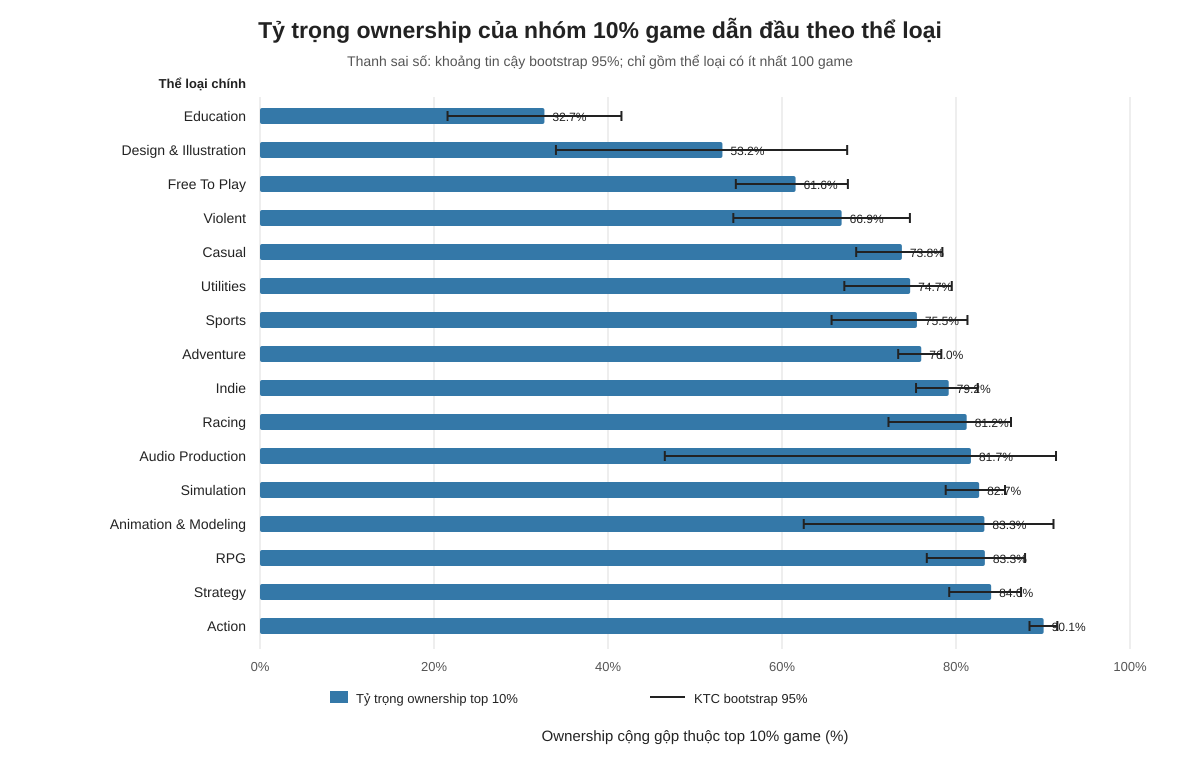

In [5]:
plot_data = genre_summary.sort_values('Top 10%', ascending=True).reset_index(drop=True)
width = 1200
left, right, top, row_gap = 260, 70, 105, 34
plot_width = width - left - right
plot_height = len(plot_data) * row_gap
bottom = top + plot_height
height = bottom + 120
parts = svg_start(
    width, height,
    'Tỷ trọng ownership của nhóm 10% game dẫn đầu theo thể loại',
    'Thanh sai số: khoảng tin cậy bootstrap 95%; chỉ gồm thể loại có ít nhất 100 game'
)
parts.append(svg_text('Thể loại chính', left-14, top-17, 13, 'end', weight='bold'))
for tick in range(0, 101, 20):
    x = left + plot_width * tick / 100
    parts.append(f'<line x1="{x}" y1="{top-8}" x2="{x}" y2="{bottom}" stroke="#dddddd"/>')
    parts.append(svg_text(f'{tick}%', x, bottom + 22, 13, 'middle', fill='#555555'))
for row, item in plot_data.iterrows():
    y = top + row * row_gap + 11
    point = 100 * item['Top 10%']
    low = 100 * item['CI dưới top 10%']
    high = 100 * item['CI trên top 10%']
    x = left + plot_width * point / 100
    x_low = left + plot_width * low / 100
    x_high = left + plot_width * high / 100
    parts.append(svg_text(item['Thể loại'], left - 14, y + 5, 14, 'end'))
    parts.append(f'<rect x="{left}" y="{y-8}" width="{plot_width*point/100}" height="16" rx="2" fill="#3478a8"/>')
    parts.append(f'<line x1="{x_low}" y1="{y}" x2="{x_high}" y2="{y}" stroke="#222222" stroke-width="2"/>')
    parts.append(f'<line x1="{x_low}" y1="{y-5}" x2="{x_low}" y2="{y+5}" stroke="#222222" stroke-width="2"/>')
    parts.append(f'<line x1="{x_high}" y1="{y-5}" x2="{x_high}" y2="{y+5}" stroke="#222222" stroke-width="2"/>')
    parts.append(svg_text(f'{point:.1f}%', min(x+8, width-right-5), y+5, 12, fill='#222222'))
legend_y = bottom + 54
parts.append(f'<rect x="{left+70}" y="{legend_y-12}" width="18" height="12" fill="#3478a8"/>')
parts.append(svg_text('Tỷ trọng ownership top 10%', left+96, legend_y, 13))
parts.append(f'<line x1="{left+390}" y1="{legend_y-6}" x2="{left+425}" y2="{legend_y-6}" stroke="#222222" stroke-width="2"/>')
parts.append(svg_text('KTC bootstrap 95%', left+434, legend_y, 13))
parts.append(svg_text('Ownership cộng gộp thuộc top 10% game (%)', left+plot_width/2, bottom+92, 15, 'middle'))
display_svg(parts)

**Diễn giải biểu đồ 1.** Action có tỷ trọng top 10% cao nhất trong so sánh thô; Education thấp nhất nhưng chỉ có 156 game. Hai đầu mút khác nhau 57,4 điểm phần trăm, song không nên xem toàn bộ khoảng cách là “hiệu ứng thể loại”: biểu đồ chưa chuẩn hóa cohort phát hành và nhóm giá. Thanh sai số biểu thị bootstrap 95%, không bao gồm sai số hệ thống của ước tính ownership.

#### Biểu đồ 2 — So sánh có kiểm soát giữa bốn thể loại lớn

Mỗi điểm là tỷ trọng top 10% sau khi lấy trung bình đều qua **cùng bảy** tầng cohort phát hành × nhóm giá. Thanh ngang là KTC bootstrap 95%. Dùng cùng các tầng giúp giảm khả năng chênh lệch chỉ phản ánh cơ cấu cohort hoặc giá khác nhau; đây vẫn là điều chỉnh cho hai biến quan sát được, không loại hết yếu tố gây nhiễu.

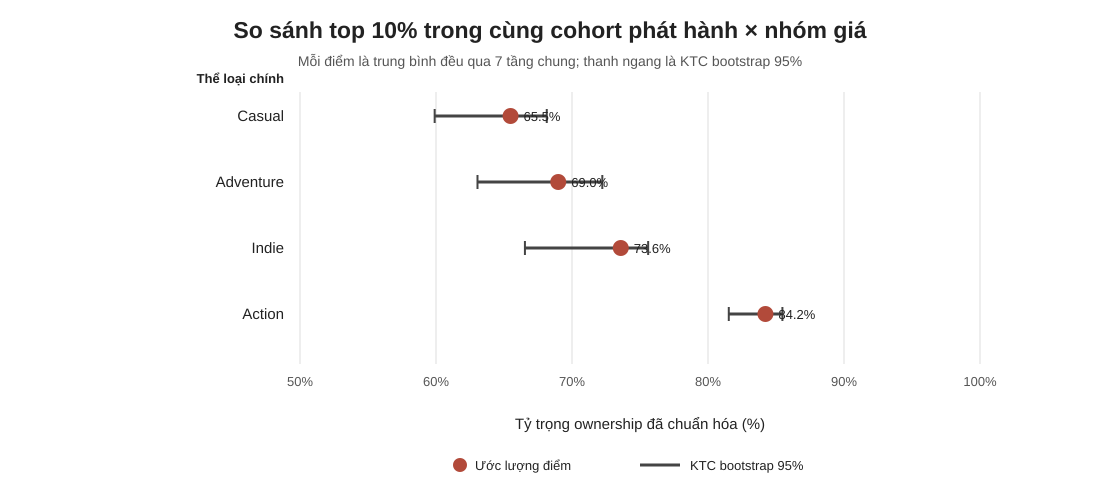

In [6]:
plot_data = adjusted_summary.sort_values(
    'Top 10% ownership đã chuẩn hóa', ascending=True
).reset_index(drop=True)
width, height = 1100, 500
left, right, top, row_gap = 300, 120, 100, 66
plot_width = width - left - right
plot_height = len(plot_data) * row_gap
bottom = top + plot_height
parts = svg_start(
    width, height,
    'So sánh top 10% trong cùng cohort phát hành × nhóm giá',
    'Mỗi điểm là trung bình đều qua 7 tầng chung; thanh ngang là KTC bootstrap 95%'
)
parts.append(svg_text('Thể loại chính', left-16, top-17, 13, 'end', weight='bold'))
for tick in range(50, 101, 10):
    x = left + plot_width * (tick - 50) / 50
    parts.append(f'<line x1="{x}" y1="{top-8}" x2="{x}" y2="{bottom}" stroke="#dddddd"/>')
    parts.append(svg_text(f'{tick}%', x, bottom + 22, 13, 'middle', fill='#555555'))
for row, item in plot_data.iterrows():
    y = top + row * row_gap + 16
    point = 100 * item['Top 10% ownership đã chuẩn hóa']
    low = 100 * item['CI dưới']
    high = 100 * item['CI trên']
    x = left + plot_width * (point - 50) / 50
    x_low = left + plot_width * (low - 50) / 50
    x_high = left + plot_width * (high - 50) / 50
    parts.append(svg_text(item['Thể loại'], left - 16, y + 5, 15, 'end'))
    parts.append(f'<line x1="{x_low}" y1="{y}" x2="{x_high}" y2="{y}" stroke="#444444" stroke-width="3"/>')
    parts.append(f'<line x1="{x_low}" y1="{y-7}" x2="{x_low}" y2="{y+7}" stroke="#444444" stroke-width="2"/>')
    parts.append(f'<line x1="{x_high}" y1="{y-7}" x2="{x_high}" y2="{y+7}" stroke="#444444" stroke-width="2"/>')
    parts.append(f'<circle cx="{x}" cy="{y}" r="8" fill="#b24a3a"/>')
    parts.append(svg_text(f'{point:.1f}%', x+13, y+5, 13, fill='#222222'))
parts.append(svg_text('Tỷ trọng ownership đã chuẩn hóa (%)', left+plot_width/2, bottom+65, 15, 'middle'))
parts.append(f'<circle cx="{left+160}" cy="{bottom+101}" r="7" fill="#b24a3a"/>')
parts.append(svg_text('Ước lượng điểm', left+175, bottom+106, 13))
parts.append(f'<line x1="{left+340}" y1="{bottom+101}" x2="{left+380}" y2="{bottom+101}" stroke="#444444" stroke-width="3"/>')
parts.append(svg_text('KTC bootstrap 95%', left+390, bottom+106, 13))
display_svg(parts)

**Diễn giải biểu đồ 2.** Sau khi chuẩn hóa trên cùng 7 tầng cohort × nhóm giá, Action vẫn cao hơn cả Adventure, Casual và Indie. Khoảng tin cậy của ước lượng điểm hỗ trợ độ bất định trong từng thể loại; bảng chênh lệch cặp định lượng trực tiếp khoảng cách giữa Action và từng nhóm. Hình này là bằng chứng chính cho so sánh có kiểm soát, nhưng chỉ điều chỉnh hai đặc điểm quan sát được và chưa hiệu chỉnh đa so sánh.

#### Biểu đồ 3 — Tỷ trọng top 10% theo cohort phát hành (D2)

Mỗi điểm tóm tắt các game thuộc thể loại/cohort đó; giá được gộp ở biểu đồ mô tả này. Chỉ hiện nhóm thể loại × cohort có ít nhất 30 game. Chú giải cho biết thể loại, còn bảng số game bên cạnh cho biết cỡ mẫu từng điểm. Cohort là nhóm game khác nhau ở một thời điểm chụp dữ liệu; không nối các điểm thành diễn biến của cùng các game qua thời gian.

Bảng cohort hiển thị 30 ô thể loại × cohort × giá đạt ngưỡng n >= 30; tổng cộng 73,947 game trong các ô đủ điều kiện.


Cohort phát hành,2010-2014,2015-2019,2020-2022,2023-2025,Đến 2009
Thể loại,,,,,
Action,0.684957,0.861776,0.860973,0.856924,0.626461
Adventure,0.622991,0.737499,0.703067,0.695558,—
Casual,0.525456,0.760710,0.623429,0.471590,—
Indie,0.713079,0.800722,0.708756,0.600013,—


Cohort phát hành,2010-2014,2015-2019,2020-2022,2023-2025,Đến 2009
Thể loại,,,,,
Action,1134,10925,9932,11301,34
Adventure,516,5454,5098,6033,0
Casual,243,4394,5047,6133,0
Indie,241,2524,2196,2742,0


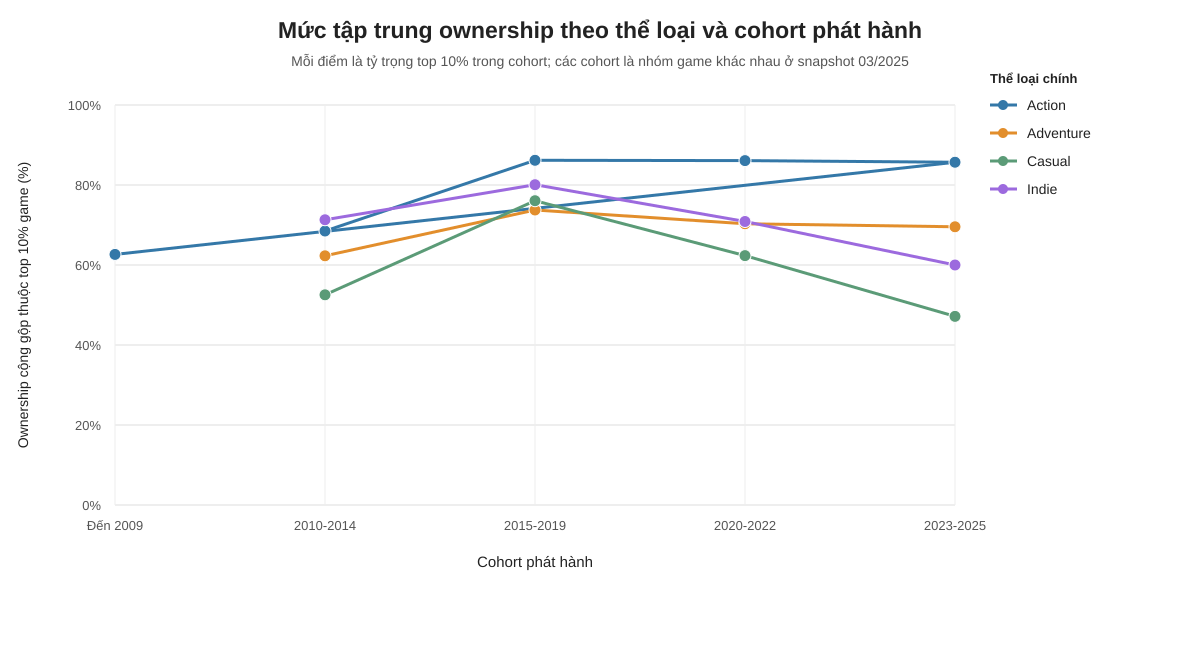

In [7]:
cohort_cells = stratum_table.loc[
    stratum_table['Thể loại'].isin(major_genres)
].copy()
print(
    f'Bảng cohort hiển thị {len(cohort_cells)} ô thể loại × cohort × giá '
    f'đạt ngưỡng n >= 30; tổng cộng {cohort_cells["Số game"].sum():,} game '
    'trong các ô đủ điều kiện.'
)
cohort_trend = (
    cohort_cells.groupby(['Thể loại', 'Cohort phát hành'], observed=True)
    .apply(lambda group: pd.Series({
        'Tỷ trọng top 10%': np.average(
            group['Top 10% ownership'], weights=group['Số game']
        ),
        'Số game': group['Số game'].sum(),
    }))
    .reset_index()
)
cohort_pivot = cohort_trend.pivot(
    index='Thể loại', columns='Cohort phát hành', values='Tỷ trọng top 10%'
).reindex(index=major_genres)
display(cohort_pivot.style.format('{:.1%}').format(na_rep='—'))
display(cohort_trend.pivot(
    index='Thể loại', columns='Cohort phát hành', values='Số game'
).reindex(index=major_genres).fillna(0).astype(int))

width, height = 1200, 650
left, right, top, bottom = 115, 245, 105, 505
plot_width, plot_height = width-left-right, bottom-top
parts = svg_start(
    width, height,
    'Mức tập trung ownership theo thể loại và cohort phát hành',
    'Mỗi điểm là tỷ trọng top 10% trong cohort; các cohort là nhóm game khác nhau ở snapshot 03/2025'
)
cohort_order = ['Đến 2009', '2010-2014', '2015-2019', '2020-2022', '2023-2025']
palette = ['#3478a8', '#e28e2c', '#5b9b77', '#9c6ade']
for tick in range(0, 101, 20):
    y = bottom - plot_height * tick / 100
    parts.append(f'<line x1="{left}" y1="{y}" x2="{left+plot_width}" y2="{y}" stroke="#dddddd"/>')
    parts.append(svg_text(f'{tick}%', left-14, y+5, 13, 'end', fill='#555555'))
for i, cohort in enumerate(cohort_order):
    x = left + plot_width * i / (len(cohort_order)-1)
    parts.append(f'<line x1="{x}" y1="{top}" x2="{x}" y2="{bottom}" stroke="#eeeeee"/>')
    parts.append(svg_text(cohort, x, bottom+25, 13, 'middle', fill='#555555'))
for color_i, genre in enumerate(major_genres):
    group = cohort_trend.loc[cohort_trend['Thể loại'].eq(genre)]
    coords = []
    for _, item in group.iterrows():
        if item['Cohort phát hành'] not in cohort_order:
            continue
        x = left + plot_width * cohort_order.index(item['Cohort phát hành']) / (len(cohort_order)-1)
        y = bottom - plot_height * item['Tỷ trọng top 10%']
        coords.append((x, y))
    for first, second in zip(coords, coords[1:]):
        parts.append(f'<line x1="{first[0]}" y1="{first[1]}" x2="{second[0]}" y2="{second[1]}" stroke="{palette[color_i]}" stroke-width="3"/>')
    for x, y in coords:
        parts.append(f'<circle cx="{x}" cy="{y}" r="6" fill="{palette[color_i]}" stroke="white" stroke-width="1"/>')
    legend_y = top + 28 * color_i
    parts.append(f'<line x1="{left+plot_width+35}" y1="{legend_y}" x2="{left+plot_width+62}" y2="{legend_y}" stroke="{palette[color_i]}" stroke-width="3"/>')
    parts.append(f'<circle cx="{left+plot_width+48}" cy="{legend_y}" r="5" fill="{palette[color_i]}"/>')
    parts.append(svg_text(genre, left+plot_width+72, legend_y+5, 14))
parts.append(svg_text('Cohort phát hành', left+plot_width/2, bottom+62, 15, 'middle'))
parts.append(svg_text('Ownership cộng gộp thuộc top 10% game (%)', 28, top+plot_height/2, 14, 'middle', extra=f'transform="rotate(-90 28 {top+plot_height/2})"'))
parts.append(svg_text('Thể loại chính', left+plot_width+35, top-22, 13, weight='bold'))
display_svg(parts)

**Diễn giải biểu đồ 3.** Tỷ trọng top 10% của Action ở các cohort đủ điều kiện khoảng 86,2% trong 2015–2019 và 85,7% trong 2023–2025. Cùng hai cohort đó, Adventure khoảng 73,7% và 69,6%; Indie 80,1% và 60,0%; Casual 76,1% và 47,2%. Mức thay đổi giữa các cohort vì thế không đồng đều giữa thể loại. Đây là mô tả nhóm game khác nhau, không phải ownership của cùng game giảm theo thời gian; bảng số game đi kèm giúp nhận biết độ phủ mẫu cho từng cohort.

### 7. Kết quả và thảo luận

#### 7.1. Trả lời trực tiếp câu hỏi

Sau các bước tiền xử lý tuần tự, còn **81.098/89.618 game** (90,5% dữ liệu đầu vào). Trong 16 thể loại có ít nhất 100 game, ước lượng mô tả top 10% ownership thấp nhất ở **Education: 32,7% (n=156)** và cao nhất ở **Action: 90,1% (n=33.332)**. Khoảng cách thô là **57,4 điểm phần trăm**. Đây là so sánh chưa điều chỉnh; số Education có cỡ mẫu nhỏ hơn nhiều và cần được xem là mô tả, không nên xếp hạng chắc chắn các thể loại nhỏ dựa trên một ước lượng duy nhất.

Để trả lời liệu khác biệt có còn khi xét đến cơ cấu game, phép so sánh chính tập trung vào bốn thể loại lớn trong bảy tầng cohort phát hành × nhóm giá chung. Tỷ trọng top 10% chuẩn hóa và khoảng tin cậy bootstrap 95% là:

| Thể loại | Tỷ trọng top 10% chuẩn hóa | KTC bootstrap 95% | Game trong 7 tầng |
|---|---:|---:|---:|
| Action | **84,2%** | 81,5%–85,5% | 33.173 |
| Indie | **73,6%** | 66,5%–75,6% | 7.703 |
| Adventure | **69,0%** | 63,1%–72,2% | 17.101 |
| Casual | **65,5%** | 59,9%–68,1% | 15.817 |

Action vẫn có tỷ trọng tập trung cao nhất trong các tầng có cùng cohort và nhóm giá. So với Action, chênh lệch chuẩn hóa là **15,23 điểm phần trăm so với Adventure** (KTC 95%: 11,09–20,96), **18,74 điểm so với Casual** (14,91–24,11), và **10,64 điểm so với Indie** (7,53–17,49). Các khoảng bootstrap cho chênh lệch đều nằm trên 0; điều này hỗ trợ nhận định rằng mức tập trung của Action cao hơn trong phạm vi mẫu và phương pháp đã chọn. Tuy nhiên, vì chưa hiệu chỉnh đa so sánh, nên diễn giải đây là các ước lượng so sánh có điều kiện, không phải kết luận khẳng định cho mọi thể loại hay toàn bộ thị trường.

#### 7.2. Diễn giải theo cohort phát hành

Trong phần mô tả theo cohort, tỷ trọng top 10% giữa các thể loại không biến động đồng nhất. Với các ô đủ ít nhất 30 game, Action khoảng **86,2%** ở cohort 2015–2019 và **85,7%** ở 2023–2025; Adventure lần lượt khoảng **73,7%** và **69,6%**; Indie khoảng **80,1%** và **60,0%**; Casual khoảng **76,1%** và **47,2%**. Mức giảm giữa hai cohort nổi bật hơn ở Casual và Indie so với Action.

Đây là khác biệt giữa **các nhóm game phát hành ở thời kỳ khác nhau**, được quan sát trong cùng snapshot tháng 03/2025. Không thể kết luận rằng độ tập trung của cùng một thể loại đã giảm theo thời gian: các game của cohort mới có thời gian tích lũy ownership ngắn hơn, đồng thời thành phần game và điều kiện thị trường cũng khác. Vì biểu đồ cohort gộp hai nhóm giá theo số game của các ô đủ điều kiện, đây là mô tả bổ trợ; kết luận so sánh chính vẫn dựa trên chuẩn hóa với nhóm giá giữ riêng thành tầng.

#### 7.3. Insight chính và điểm đáng chú ý

**Insight 1 — Action nổi bật không chỉ vì quy mô mẫu lớn.** So sánh thô cho thấy top 10% game Action chiếm 90,1% tổng ownership ước tính của thể loại. Trong phép so sánh có kiểm soát, Action vẫn dẫn đầu với tỷ trọng chuẩn hóa 84,2%, cao hơn Adventure 15,23 điểm phần trăm, Casual 18,74 điểm và Indie 10,64 điểm. Cả ba khoảng tin cậy bootstrap 95% của chênh lệch đều nằm trên 0 (lần lượt 11,09–20,96; 14,91–24,11; 7,53–17,49 điểm phần trăm). Điểm đáng chú ý là khoảng cách không biến mất khi đối chiếu trong cùng cohort phát hành và nhóm giá; vì vậy, riêng khác biệt về hai đặc điểm này chưa giải thích hết mẫu hình quan sát được. Tuy nhiên, đây không phải bằng chứng rằng bản thân nhãn Action gây ra mức tập trung cao hơn: những yếu tố khác như thương hiệu, quy mô phát hành, thời lượng tồn tại, marketing và chất lượng game chưa được kiểm soát.

**Insight 2 — Trung bình của thị trường có thể bị kéo mạnh bởi nhóm dẫn đầu.** Tỷ trọng 84,2% của Action được chuẩn hóa bằng cách lấy trung bình ngang nhau tỷ trọng của bảy tầng cohort × nhóm giá chung; nó không phải tỷ lệ gộp tính trên toàn bộ 33.173 game của Action trong tập so sánh. Dù vậy, kết quả cho thấy trong từng cấu phần so sánh, phần ownership ước tính tập trung đáng kể vào nhóm game đứng đầu. Với người ra quyết định, điều này cảnh báo rằng số tổng của cả thể loại có thể tạo cảm giác về một thị trường rộng và đồng đều, trong khi kết quả thực tế của một tựa game riêng lẻ có thể khác xa các tựa dẫn đầu. Chỉ số này không cho biết “game điển hình” có bao nhiêu ownership; muốn trả lời cần xem thêm trung vị, phân vị và phân phối theo từng game.

**Insight 3 — Cohort mới không cho thấy một xu hướng giảm giống nhau ở mọi thể loại.** So sánh mô tả 2015–2019 với 2023–2025 cho thấy Action gần như ổn định (86,2% xuống 85,7%, chênh -0,5 điểm phần trăm), Adventure giảm khoảng 4,2 điểm (73,7% xuống 69,6%), trong khi Indie giảm khoảng 20,1 điểm (80,1% xuống 60,0%) và Casual giảm khoảng 28,9 điểm (76,1% xuống 47,2%). Sự khác nhau về độ lớn gợi ý rằng cấu trúc ownership của các thế hệ phát hành có thể không đồng nhất giữa thể loại. Đây là tín hiệu đáng để kiểm tra tiếp, không phải bằng chứng rằng game mới của Casual hay Indie sẽ kém thành công: cohort mới có ít thời gian tích lũy ownership hơn, các game trong mỗi cohort khác nhau về thành phần, và thống kê được tính tại một snapshot duy nhất.

**Insight 4 — Thứ hạng Action bền hơn độ lớn tuyệt đối.** Khi đổi định nghĩa nhóm dẫn đầu từ top 5% sang top 20%, Action lần lượt đạt 75,4%, 84,2% và 90,5% nhưng vẫn đứng đầu trong bốn thể loại. Khi dùng cận dưới/trung điểm/cận trên ownership, Action đạt 88,8%/84,2%/82,4% và vẫn giữ vị trí cao nhất. Ngược lại, khoảng dao động đáng kể cho thấy không nên xem 84,2% như một hằng số chính xác của thị trường: con số phụ thuộc vào ngưỡng nhóm dẫn đầu và cách biểu diễn khoảng ownership. Kết luận hợp lý hơn là thứ hạng tương đối của Action ổn định trong các kịch bản đã thử, còn độ lớn cần được báo cáo kèm định nghĩa và phân tích độ nhạy.

#### 7.4. Ý nghĩa thực tế theo nhóm đối tượng

**Studio độc lập hoặc nhóm phát triển nhỏ.** Kết quả không nói thể loại nào dễ thành công hơn, nhưng cho thấy không nên lấy những tựa dẫn đầu làm đại diện cho mức kết quả có thể kỳ vọng của cả phân khúc. Khi đánh giá cơ hội, studio có thể dùng tỷ trọng tập trung như một chỉ báo sàng lọc để đặt câu hỏi tiếp: phần lớn ownership có nằm ở vài thương hiệu lâu đời không; có nhóm game quy mô vừa đủ lớn để tạo chuẩn so sánh thực tế không; và một sản phẩm mới cần khác biệt ở đâu để không chỉ cạnh tranh trực tiếp với các tựa dẫn đầu? Trước khi quyết định sản xuất, cần bổ sung phân phối ownership, thời gian phát hành, đánh giá người dùng, mức cập nhật, chi phí tiếp thị và dữ liệu doanh thu/hoạt động.

**Nhà phát hành và nhóm nghiên cứu thị trường.** Khi lập báo cáo quy mô thể loại, nên trình bày đồng thời tổng ownership, số lượng game, tỷ trọng của nhóm đầu và các phân vị của phân phối. Cách trình bày này giúp phân biệt một phân khúc có nhiều tựa cùng đóng góp với một phân khúc có tổng lớn nhưng tập trung vào số ít tựa. Kết quả cohort cũng gợi ý nên phân tầng theo năm phát hành thay vì gộp game cũ và mới: ownership tích lũy chịu ảnh hưởng của thời gian hiện diện. Có thể dùng phát hiện để xác định nơi cần phân tích sâu hơn, nhưng không nên dùng nó một mình để dự báo doanh thu, xác suất thành công hay phân bổ ngân sách.

**Nhà nghiên cứu hoặc người xây dựng chính sách nền tảng.** Chênh lệch giữa các thể loại sau khi chuẩn hóa là căn cứ mô tả để khảo sát thêm tính không đồng đều của phân phối ownership. Để đánh giá cạnh tranh hoặc mức độ phụ thuộc vào một vài tựa game, cần có thêm thước đo như đường cong Lorenz/Gini, CR5/CR10 được tính trên cùng đơn vị, và dữ liệu theo thời gian. Dataset hiện tại không cho phép suy ra hành vi đề xuất của nền tảng, quyền lực thị trường hay tác động của chính sách; các khái niệm đó cần biến đo lường và thiết kế nghiên cứu riêng.

#### 7.5. Đối chiếu giả thuyết và phạm vi kết luận

- **H1 — Mức tập trung khác nhau theo thể loại:** được hỗ trợ về mặt mô tả; đặc biệt, Action cao hơn ba thể loại đối chiếu trong phép chuẩn hóa đã thực hiện. Không nên khái quát kết quả của bốn thể loại lớn thành kết luận cho mọi thể loại.
- **H2 — Khác biệt còn sau khi so sánh các nhóm tương đồng:** được hỗ trợ trong bảy tầng cohort phát hành × nhóm giá chung. Đây là kiểm soát có giới hạn, không loại trừ các yếu tố gây nhiễu chưa quan sát.
- **H3 — Kết luận bền với lựa chọn phân tích:** thứ hạng Action cao nhất giữ nguyên khi thay ngưỡng top 5%/10%/20% và khi dùng cận dưới/trung điểm/cận trên. Độ lớn thay đổi đáng kể, nên cần phân biệt độ bền về thứ hạng với độ chính xác của một con số cụ thể.

**Phạm vi diễn giải:** kết quả đo mức tập trung của tổng ownership ước tính giữa các tựa game trong snapshot. Nó không phải số người chơi duy nhất, người đang hoạt động, retention, CCU, doanh thu, lợi nhuận hay khả năng thành công của một game mới. Các chênh lệch là liên hệ mô tả, không chứng minh quan hệ nhân quả.

### 8. Kiểm tra độ bền vững (D6)

Độ bền vững được đánh giá bằng cách giữ nguyên bốn thể loại và bảy tầng cohort × nhóm giá chung, chỉ thay đổi một lựa chọn phân tích tại mỗi lần kiểm tra:

1. **Thay ngưỡng nhóm dẫn đầu:** so sánh top 5%, top 10% và top 20% theo trung điểm ownership.
2. **Thay đại diện cho khoảng ownership:** tính lại top 10% bằng cận dưới, trung điểm và cận trên của `estimated_owners`.

Các kịch bản cận dưới/cận trên là kiểm tra độ nhạy trước khoảng đo lường trong dữ liệu nguồn; chúng không phải khoảng tin cậy. Phân tích kiểm tra liệu thứ hạng tương đối có giữ nguyên, đồng thời ghi nhận độ lớn của tỷ trọng có phụ thuộc vào định nghĩa hay không.

,Thể loại,Top 5%,Top 10%,Top 20%
0,Action,75.4%,84.2%,90.5%
1,Adventure,58.6%,69.0%,79.7%
2,Casual,56.6%,65.5%,75.2%
3,Indie,62.4%,73.6%,82.1%


,Thể loại,Cận dưới,Trung điểm,Cận trên
0,Action,88.8%,84.2%,82.4%
1,Adventure,78.6%,69.0%,65.7%
2,Casual,83.8%,65.5%,60.9%
3,Indie,84.5%,73.6%,70.0%


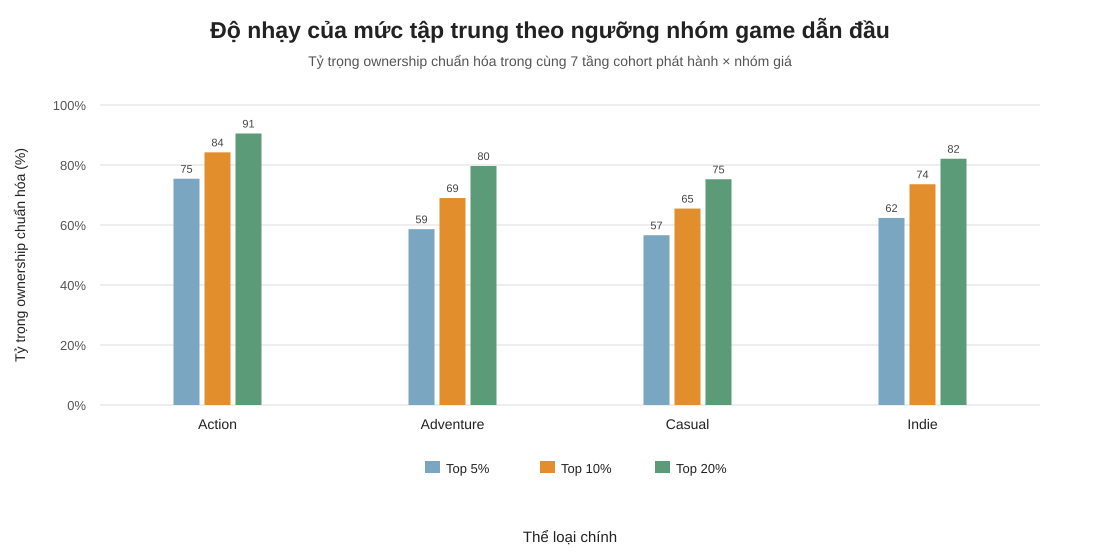

In [8]:
sensitivity_rows = []
for genre in major_genres:
    row = {'Thể loại': genre}
    for fraction in fractions:
        row[f'Top {int(fraction * 100)}%'] = point_by_genre[genre][fraction]
    sensitivity_rows.append(row)
sensitivity_fraction = pd.DataFrame(sensitivity_rows)
display(sensitivity_fraction.style.format({
    'Top 5%': '{:.1%}',
    'Top 10%': '{:.1%}',
    'Top 20%': '{:.1%}',
}))

endpoint_rows = []
for genre in major_genres:
    row = {'Thể loại': genre}
    for bound in ['owners_lower', 'owners_midpoint', 'owners_upper']:
        stratum_estimates = []
        for period, price_group in common_strata:
            group = analysis.loc[
                analysis['primary_genre'].eq(genre)
                & analysis['release_period'].astype(str).eq(period)
                & analysis['price_group'].eq(price_group),
                bound,
            ].to_numpy()
            stratum_estimates.append(concentration_share(group, 0.10))
        row[bound] = float(np.mean(stratum_estimates))
    endpoint_rows.append(row)
endpoint_sensitivity = pd.DataFrame(endpoint_rows).rename(columns={
    'owners_lower': 'Cận dưới',
    'owners_midpoint': 'Trung điểm',
    'owners_upper': 'Cận trên',
})
display(endpoint_sensitivity.style.format({
    'Cận dưới': '{:.1%}',
    'Trung điểm': '{:.1%}',
    'Cận trên': '{:.1%}',
}))

width, height = 1100, 560
left, right, top, bottom = 100, 60, 105, 405
plot_width, plot_height = width-left-right, bottom-top
parts = svg_start(
    width, height,
    'Độ nhạy của mức tập trung theo ngưỡng nhóm game dẫn đầu',
    'Tỷ trọng ownership chuẩn hóa trong cùng 7 tầng cohort phát hành × nhóm giá'
)
for tick in range(0, 101, 20):
    y = bottom - plot_height * tick / 100
    parts.append(f'<line x1="{left}" y1="{y}" x2="{left+plot_width}" y2="{y}" stroke="#dddddd"/>')
    parts.append(svg_text(f'{tick}%', left-14, y+5, 13, 'end', fill='#555555'))
bar_width, group_gap = 26, plot_width/len(major_genres)
colors = ['#7aa6c2', '#e28e2c', '#5b9b77']
for genre_i, genre in enumerate(major_genres):
    center = left + group_gap * (genre_i + 0.5)
    parts.append(svg_text(genre, center, bottom+24, 14, 'middle'))
    for fraction_i, fraction in enumerate(fractions):
        value = 100 * point_by_genre[genre][fraction]
        x = center + (fraction_i-1) * (bar_width+5) - bar_width/2
        y = bottom - plot_height * value / 100
        bar_height = bottom-y
        parts.append(f'<rect x="{x}" y="{y}" width="{bar_width}" height="{bar_height}" fill="{colors[fraction_i]}"/>')
        parts.append(svg_text(f'{value:.0f}', x+bar_width/2, y-6, 11, 'middle', fill='#444444'))
legend_y = bottom+68
for i, fraction in enumerate(fractions):
    x = left+plot_width/2-145+i*115
    parts.append(f'<rect x="{x}" y="{legend_y-12}" width="15" height="12" fill="{colors[i]}"/>')
    parts.append(svg_text(f'Top {int(fraction*100)}%', x+21, legend_y, 13))
parts.append(svg_text('Thể loại chính', left+plot_width/2, height-18, 15, 'middle'))
parts.append(svg_text('Tỷ trọng ownership chuẩn hóa (%)', 25, top+plot_height/2, 14, 'middle', extra=f'transform="rotate(-90 25 {top+plot_height/2})"'))
display_svg(parts)

**Diễn giải kiểm tra độ bền vững.** Action vẫn có tỷ trọng chuẩn hóa cao nhất ở cả ba ngưỡng: **75,4% (top 5%)**, **84,2% (top 10%)**, **90,5% (top 20%)**. Khi thay trung điểm bằng cận dưới/cận trên, Action lần lượt là **88,8%**, **84,2%**, **82,4%** và vẫn đứng đầu. Thứ hạng dẫn đầu của Action do đó bền với các lựa chọn đã thử; độ lớn tuyệt đối thay đổi, và vị trí giữa Adventure/Casual/Indie nhạy hơn. Cận ownership là kịch bản độ nhạy, không phải khoảng tin cậy.

### 9. Giới hạn phân tích

1. **Ownership là khoảng ước tính, không phải số đếm chính xác.** Trung điểm là một quy ước đại diện cho khoảng; kết quả theo cận dưới và cận trên khác đáng kể về độ lớn. Bootstrap lượng hóa biến thiên lấy mẫu game có điều kiện trên các giá trị đã quan sát, không bao hàm sai số hệ thống hay bất định do cách Steam ước lượng ownership.
2. **Không suy ra quy mô người dùng duy nhất hoặc hoạt động hiện tại.** Một người có thể sở hữu nhiều game; cộng ownership qua các tựa có thể đếm lặp người. Snapshot ownership tích lũy không đo người đang chơi, CCU, retention hay mức hài lòng.
3. **Quy tắc thể loại chính làm đơn giản hóa game đa thể loại.** Mỗi game chỉ được xếp vào nhãn đầu tiên trong danh sách. Kết quả vì vậy phụ thuộc một phần vào thứ tự nhãn và không mô tả đầy đủ các thể loại phụ.
4. **Cohort không phải dữ liệu bảng theo dõi thời gian.** Các cohort gồm những game khác nhau và được quan sát tại một snapshot tháng 03/2025. Game cũ có nhiều thời gian tích lũy ownership hơn; nhóm 2023–2025 có thời gian quan sát ngắn và năm 2025 chưa trọn vẹn. Không thể diễn giải chênh lệch cohort như biến động của cùng một game.
5. **Kiểm soát yếu tố gây nhiễu còn hạn chế.** So sánh chuẩn hóa giữ cố định cohort phát hành và nhóm giá, nhưng chưa điều chỉnh đồng thời cho nhà phát hành, marketing, chất lượng, cập nhật, nền tảng, giảm giá, thời điểm ra mắt hoặc những khác biệt khác. `price = 0` chỉ mô tả giá tại snapshot, không đủ để xác định toàn bộ mô hình kinh doanh.
6. **Phạm vi so sánh có điều kiện.** Phân tích chuẩn hóa chỉ xét bốn thể loại lớn và bảy tầng chung có ít nhất 30 game của mỗi thể loại; 242 game thuộc bốn thể loại này nằm ngoài các tầng chung. Kết quả không đại diện tự động cho thể loại nhỏ hoặc toàn bộ danh mục Steam. Ngưỡng 100 game cho bảng tổng quan cũng là quy tắc trình bày, không phải ngưỡng suy luận phổ quát.
7. **Bất định bootstrap phụ thuộc giả định lấy mẫu.** Bootstrap lấy game làm đơn vị và coi các game trong tầng là có thể lấy mẫu lại độc lập. Tựa game có thể liên hệ qua cùng nhà phát hành, thương hiệu hoặc chuỗi game; sự phụ thuộc này không được mô hình hóa và có thể khiến khoảng tin cậy hẹp hơn độ bất định thực tế.
8. **Các so sánh nhiều cặp chưa hiệu chỉnh đa kiểm định.** Ba khoảng tin cậy của Action so với các thể loại khác cần được xem trong bối cảnh nhiều phép so sánh; chúng không thay thế một thiết kế kiểm định xác nhận có điều chỉnh.
9. **Không có suy luận nhân quả.** Mối liên hệ quan sát được không chứng minh thể loại, cohort hay giá gây ra mức tập trung; cũng không đủ để dự báo kết quả của game mới hoặc xác định xác suất sinh lời.

### 10. Kết luận

**Trả lời câu hỏi:** tỷ trọng ownership ước tính cộng gộp thuộc về nhóm 10% game dẫn đầu khác nhau giữa các thể loại. Trong so sánh chuẩn hóa trên cùng bảy tầng cohort phát hành × nhóm giá, ước lượng là **84,2% ở Action**, **73,6% ở Indie**, **69,0% ở Adventure** và **65,5% ở Casual**. Chênh lệch của Action so với Adventure, Casual và Indie lần lượt là **15,23**, **18,74** và **10,64 điểm phần trăm**; các khoảng tin cậy bootstrap 95% cho các chênh lệch này đều nằm trên 0 trong phân tích chưa hiệu chỉnh đa so sánh.

Thứ hạng Action cao nhất không đổi khi kiểm tra top 5%/10%/20% và khi dùng cận dưới hoặc cận trên của khoảng ownership. Do đó, kết quả ủng hộ kết luận rằng ownership ước tính trong các game Action quan sát được tập trung vào nhóm tựa dẫn đầu hơn so với ba thể loại lớn được đối chiếu. Kết luận này chỉ áp dụng trong phạm vi mẫu, định nghĩa ownership, cohort/nhóm giá và quy tắc chọn mẫu đã nêu; không đồng nghĩa Action có tổng ownership lớn nhất, cũng không chứng minh thể loại Action gây ra mức tập trung.

Về ứng dụng, khi đánh giá một phân khúc game, nên báo cáo **cả quy mô ownership cộng gộp lẫn cách ownership phân bố giữa các tựa**, đồng thời nêu cỡ mẫu và độ bất định. Chỉ số tập trung có thể hỗ trợ phân tích danh mục và đặt giả thuyết về sự phụ thuộc vào các tựa dẫn đầu; nó không phải thước đo số người chơi duy nhất, doanh thu, lợi nhuận hay xác suất thành công của game mới.